# Computational Intelligence Project: Solving Generalized Klotski using BFS and A* Search

## 1. Project Introduction
Search algorithms form a foundational pillar of Artificial Intelligence and Computational Intelligence, enabling autonomous agents to solve complex puzzles, plan actions, and navigate large state spaces. In this project, we implement, analyze, and compare two classic graph search algorithms—**Breadth-First Search (BFS)** as an uninformed search method, and **A\* Search** as an informed (heuristic-guided) search method—to find optimal solutions for the **Generalized Klotski** sliding-block puzzle.

## 2. Problem Definition
**Generalized Klotski** is played on a rectangular grid of size $R \times C$ containing empty cells (`.`) and various rectangular pieces of different dimensions (e.g., $1 \times 1$, $1 \times 2$, $2 \times 1$, $2 \times 2$). Cells sharing the same alphanumeric label belong to a single rigid piece that must move as one unit.

* **Initial State:** The starting configuration of pieces on the $R \times C$ board as specified in the problem instance.
* **Valid Actions (Unit-Step Metric):** In our problem formulation, a single valid move consists of sliding any single piece by **exactly one grid cell** in one of four cardinal directions (`UP`, `DOWN`, `LEFT`, `RIGHT`), provided that all destination cells newly occupied by that piece are currently empty (`.`) and within board boundaries. Every 1-cell slide has a uniform step cost of $1$.
* **Goal State:** Any board configuration in which the designated `target` piece (e.g., piece `A`) sits at the bottom edge of the board and completely covers the specified `exit bottom` column indices (0-indexed from left to right).

## 3. Background and Theoretical Concepts
To solve Klotski systematically, we model the puzzle as a **State-Space Graph**:
* **Node (State):** Represents a unique arrangement of all pieces on the board at a given moment.
* **Edge (Action/Transition):** Connects one board state to another via a single valid 1-cell piece movement.
* **Search Space:** The complete set of all reachable board configurations starting from the initial board.
* **Path:** A sequence of valid moves transforming the initial state into another state. An **optimal path** achieves the goal state in the minimum possible number of moves.
* **Uninformed vs. Informed Search:**
  * *Uninformed (Blind) Search* explores the search space systematically without any clue about which states are closer to the goal (e.g., **BFS**).
  * *Informed (Heuristic) Search* leverages domain-specific knowledge via a heuristic function $h(n)$ to estimate how many moves remain to reach the goal, prioritizing more promising states (e.g., **A\***).

## 4. Problem Parser and Board Utilities
This section handles parsing problem specifications from the benchmark dataset and defines helper utilities to inspect the board states.

In [258]:
def load_klotski_problems(filepath):
    """
    Reads the benchmark file and parses all Klotski problem instances.
    Returns a dictionary mapping problem_id -> problem_data dictionary.
    """
    problems = {}
    
    with open(filepath, 'r', encoding='utf-8') as file:
        lines = [line.strip() for line in file]
        
    i = 0
    while i < len(lines):
        line = lines[i]
        
        # Skip empty lines and comment lines starting with '#'
        if not line or line.startswith('#'):
            i += 1
            continue
            
        # Start parsing a new problem block
        if line.startswith('problem'):
            prob_id = line.split()[1]
            
            # Next line: size <rows> <cols>
            i += 1
            size_parts = lines[i].split()
            rows, cols = int(size_parts[1]), int(size_parts[2])
            
            # Next line: exit bottom <columns...>
            i += 1
            exit_parts = lines[i].split()
            # Extract all column indices listed after 'exit bottom'
            exit_cols = [int(c) for c in exit_parts[2:]]
            
            # Next line: target <piece>
            i += 1
            target_piece = lines[i].split()[1]
            
            # Next line is the top border '========='
            i += 1  # Now at '========='
            i += 1  # Move to the first board row
            
            board_rows = []
            while i < len(lines) and not lines[i].startswith('========='):
                # Split by whitespace to handle multi-character tokens like '10' cleanly
                row_tokens = tuple(lines[i].split())
                board_rows.append(row_tokens)
                i += 1
                
            # Store the board as a tuple of tuples so it is immutable and hashable!
            initial_board = tuple(board_rows)
            
            problems[prob_id] = {
                'id': prob_id,
                'rows': rows,
                'cols': cols,
                'exit_cols': exit_cols,
                'target': target_piece,
                'initial_board': initial_board
            }
            
        i += 1
        
    return problems

In [259]:
def print_board(board):
    """Prints a Klotski board state neatly in the console."""
    cols = len(board[0])
    border = "=" * (cols * 3 + 1)
    print(border)
    for row in board:
        # Format each cell to width 2 for clean alignment (e.g., piece '10' in p02)
        formatted_row = " ".join(f"{cell:>2}" for cell in row)
        print(f" {formatted_row}")
    print(border)

In [260]:
# --- Test loading and displaying the problems ---
problems = load_klotski_problems('klotski_problems.txt')
print(f"Successfully loaded {len(problems)} problems: {list(problems.keys())}\n")

Successfully loaded 6 problems: ['p01', 'p02', 'p03', 'p04', 'p05', 'p06']



In [261]:
# Let's inspect problem p01 and p02 to verify!
for pid in ['p01', 'p02']:
    p = problems[pid]
    print(f"Problem ID: {p['id']} | Size: {p['rows']}x{p['cols']} | Target: '{p['target']}' | Exit Columns: {p['exit_cols']}")
    print_board(p['initial_board'])
    print()

Problem ID: p01 | Size: 3x3 | Target: 'A' | Exit Columns: [1]
  A  5  1
  6  4  2
  3  .  .

Problem ID: p02 | Size: 4x4 | Target: 'A' | Exit Columns: [1, 2]
  A  A  4  7
  A  A  6  8
  1  5  .  3
 10  .  9  2



## 5. State Transitions and Successor Generation
Here we formulate the physics and transition dynamics of the game. A piece can slide by exactly 1 grid cell into unoccupied space (`.`).

In [262]:
def get_pieces(board):
    """
    Scans the board and groups coordinates belonging to each distinct piece.
    Returns:
        pieces: dict mapping piece_name -> list of (row, col) coordinates
    """
    pieces = {}
    rows = len(board)
    cols = len(board[0])
    for r in range(rows):
        for c in range(cols):
            token = board[r][c]
            if token != '.':
                if token not in pieces:
                    pieces[token] = []
                pieces[token].append((r, c))
    return pieces

In [263]:
def is_goal(board, target_piece, exit_cols):
    """
    Checks if the goal condition is met:
    Target piece must occupy all designated exit columns on the bottom row.
    """
    last_row = len(board) - 1
    for col in exit_cols:
        if board[last_row][col] != target_piece:
            return False
    return True

In [264]:
# The 4 cardinal directions: (delta_row, delta_col, direction_name)
DIRECTIONS = [
    (-1, 0, 'UP'),
    (1, 0, 'DOWN'),
    (0, -1, 'LEFT'),
    (0, 1, 'RIGHT')
]

In [265]:
def get_successors(board):
    """
    Generates all valid next board states reachable by sliding any piece
    by exactly 1 grid cell (unit-step metric).
    
    Returns a list of tuples: (next_board, piece_moved, direction)
    """
    rows = len(board)
    cols = len(board[0])
    pieces = get_pieces(board)
    successors = []

    for piece, cells in pieces.items():
        cell_set = set(cells)
        for dr, dc, direction_name in DIRECTIONS:
            can_move = True
            new_cells = []
            
            for r, c in cells:
                nr, nc = r + dr, c + dc
                
                # Check 1: Must stay within board boundaries
                if not (0 <= nr < rows and 0 <= nc < cols):
                    can_move = False
                    break
                
                # Check 2: Destination must be empty or currently part of this same piece
                dest_cell = board[nr][nc]
                if dest_cell != '.' and (nr, nc) not in cell_set:
                    can_move = False
                    break
                    
                new_cells.append((nr, nc))
                
            if can_move:
                # Build the new board after this valid 1-step slide
                board_list = [list(row) for row in board]
                
                # 1. Clear previous cells of this piece
                for r, c in cells:
                    board_list[r][c] = '.'
                    
                # 2. Place piece at the new coordinates
                for nr, nc in new_cells:
                    board_list[nr][nc] = piece
                    
                # Convert back to immutable tuple of tuples
                next_board = tuple(tuple(row) for row in board_list)
                successors.append((next_board, piece, direction_name))

    return successors

In [266]:
# --- Quick Test of Successors on Problem p01 ---
p01 = problems['p01']
print("Initial Board for p01:")
print_board(p01['initial_board'])
print(f"Is initial board already goal? {is_goal(p01['initial_board'], p01['target'], p01['exit_cols'])}")

succs = get_successors(p01['initial_board'])
print(f"\nNumber of valid moves from start: {len(succs)}")
for i, (b, piece, direction) in enumerate(succs, 1):
    print(f"\nMove {i}: Piece '{piece}' moved {direction}")
    print_board(b)

Initial Board for p01:
  A  5  1
  6  4  2
  3  .  .
Is initial board already goal? False

Number of valid moves from start: 3

Move 1: Piece '4' moved DOWN
  A  5  1
  6  .  2
  3  4  .

Move 2: Piece '2' moved DOWN
  A  5  1
  6  4  .
  3  .  2

Move 3: Piece '3' moved RIGHT
  A  5  1
  6  4  2
  .  3  .


## 6. State Canonicalization (Symmetry Breaking)
Klotski puzzles frequently feature multiple identical pieces (e.g., several $1 \times 1$ or $2 \times 1$ blocks). Swapping two identical pieces creates distinct textual representations for mathematically identical configurations. State canonicalization maps symmetric board states to a unique standard representation, drastically pruning redundant branches in the search space.

In [267]:
def canonical_board(board, target_piece):
    """
    Normalizes identical pieces to eliminate symmetric duplicate states.
    Pieces of the same dimensions are re-labeled deterministically based on
    their first appearance when scanning the board top-to-bottom, left-to-right.
    The target piece retains its original identity.
    """
    rows = len(board)
    cols = len(board[0])
    pieces = get_pieces(board)
    
    # Extract dimensions (height, width) for each piece
    piece_shapes = {}
    for p, cells in pieces.items():
        if p == target_piece:
            piece_shapes[p] = ('TARGET', len(cells))
        else:
            r_coords = [r for r, c in cells]
            c_coords = [c for r, c in cells]
            h = max(r_coords) - min(r_coords) + 1
            w = max(c_coords) - min(c_coords) + 1
            piece_shapes[p] = (h, w)
            
    shape_counters = {}
    label_map = {'.': '.', target_piece: target_piece}
    
    canonical_grid = []
    for r in range(rows):
        row = []
        for c in range(cols):
            token = board[r][c]
            if token == '.' or token == target_piece:
                row.append(token)
            else:
                if token not in label_map:
                    shape = piece_shapes[token]
                    count = shape_counters.get(shape, 0)
                    shape_counters[shape] = count + 1
                    label_map[token] = f"{shape[0]}x{shape[1]}_{count}"
                row.append(label_map[token])
        canonical_grid.append(tuple(row))
        
    return tuple(canonical_grid)

## 7. Breadth-First Search (BFS)
Breadth-First Search (BFS) is a fundamental uninformed graph search algorithm. It begins at the root node and systematically explores all neighboring nodes at the current depth level before moving on to nodes at the next depth level.

### Key Characteristics:
* **Frontier Data Structure:** Uses a First-In, First-Out (FIFO) queue (`collections.deque`).
* **Completeness:** Complete (always finds a solution if one exists in a finite graph).
* **Optimality:** Optimal when step costs are uniform (each slide costs 1 move).
* **Time Complexity:** $O(b^d)$, where $b$ is the branching factor and $d$ is the shallowest goal depth.
* **Space Complexity:** $O(b^d)$, as all generated states at the frontier and explored set reside in memory.

In [268]:
from collections import deque
import time

In [269]:
def solve_bfs(problem):
    initial_board = problem['initial_board']
    target_piece = problem['target']
    exit_cols = problem['exit_cols']
    
    if is_goal(initial_board, target_piece, exit_cols):
        return {
            'solved': True,
            'path': [],
            'moves': 0,
            'nodes_explored': 0,
            'time_sec': 0.0
        }

    start_time = time.time()
    
    # Store tuples: (current_board, path_of_actions)
    frontier = deque([(initial_board, [])])
    
    # Visited stores CANONICAL states to eliminate symmetric duplicates
    initial_canon = canonical_board(initial_board, target_piece)
    visited = {initial_canon}
    
    nodes_explored = 0
    
    while frontier:
        current_board, path = frontier.popleft()
        nodes_explored += 1
        
        for next_board, piece, direction in get_successors(current_board):
            canon_next = canonical_board(next_board, target_piece)
            
            if canon_next not in visited:
                new_path = path + [(piece, direction)]
                
                if is_goal(next_board, target_piece, exit_cols):
                    elapsed_time = time.time() - start_time
                    return {
                        'solved': True,
                        'path': new_path,
                        'moves': len(new_path),
                        'nodes_explored': nodes_explored,
                        'time_sec': elapsed_time
                    }
                    
                visited.add(canon_next)
                frontier.append((next_board, new_path))
                
    elapsed_time = time.time() - start_time
    return {
        'solved': False,
        'path': [],
        'moves': 0,
        'nodes_explored': nodes_explored,
        'time_sec': elapsed_time
    }

In [270]:
# --- Test BFS on problem p01 ---
p01 = problems['p01']
print("Running BFS on problem p01...")
bfs_result_p01 = solve_bfs(p01)

print("\n--- BFS Results for p01 ---")
print(f"Solved: {bfs_result_p01['solved']}")
print(f"Total Moves: {bfs_result_p01['moves']}")
print(f"Nodes Explored: {bfs_result_p01['nodes_explored']}")
print(f"Execution Time: {bfs_result_p01['time_sec']:.4f} seconds")
print("\nAction Path:")
for step_num, (pc, dr) in enumerate(bfs_result_p01['path'], 1):
    print(f"Step {step_num:>2}: Move piece '{pc}' {dr}")

Running BFS on problem p01...

--- BFS Results for p01 ---
Solved: True
Total Moves: 8
Nodes Explored: 80
Execution Time: 0.0040 seconds

Action Path:
Step  1: Move piece '4' DOWN
Step  2: Move piece '5' DOWN
Step  3: Move piece 'A' RIGHT
Step  4: Move piece '6' UP
Step  5: Move piece '5' LEFT
Step  6: Move piece 'A' DOWN
Step  7: Move piece '4' RIGHT
Step  8: Move piece 'A' DOWN


## 8. A* Search Algorithm
A* Search is an informed graph traversal algorithm. It directs exploration toward the goal by evaluating states using a cost evaluation function:
$$f(n) = g(n) + h(n)$$
where $g(n)$ represents the exact cost accumulated from the initial state to node $n$, and $h(n)$ is an admissible heuristic estimating the minimum cost to reach the goal from node $n$.

### Heuristic Design:
* **Manhattan Distance to Exit:** Calculates the vertical and horizontal grid distance between target piece $A$ and the goal coordinates at the bottom exit.
* **Blocking Obstacle Penalty:** Detects unique obstacle pieces occupying the vertical corridor directly beneath the target piece and the exit columns.
* **Admissibility & Optimality:** Since Manhattan distance reflects the bare minimum steps required even on an empty board and obstacles must clear out with at least one move, our heuristic does not overestimate the true cost ($h(n) \le h^*(n)$), ensuring A* yields optimal solutions.

In [271]:
import heapq

def heuristic_klotski(board, target_piece, exit_cols):
    """
    Computes an admissible heuristic h(n) for a Klotski board:
    1. Manhattan distance from target piece to bottom exit.
    2. Count of distinct obstacle pieces directly blocking the path to the exit.
    """
    rows = len(board)
    cols = len(board[0])
    pieces = get_pieces(board)
    
    if target_piece not in pieces:
        return 0
        
    target_cells = pieces[target_piece]
    target_min_r = min(r for r, c in target_cells)
    target_max_r = max(r for r, c in target_cells)
    target_min_c = min(c for r, c in target_cells)
    
    # Target piece dimensions
    target_height = target_max_r - target_min_r + 1
    goal_row = rows - target_height
    goal_col = min(exit_cols)
    
    # Base Manhattan distance
    h_dist = abs(target_min_r - goal_row) + abs(target_min_c - goal_col)
    
    # Count unique obstacle pieces blocking the exit path directly below target piece
    blocking_pieces = set()
    for r in range(target_max_r + 1, rows):
        for c in exit_cols:
            token = board[r][c]
            if token != '.' and token != target_piece:
                blocking_pieces.add(token)
                
    return h_dist + len(blocking_pieces)

In [272]:
def solve_astar(problem):
    initial_board = problem['initial_board']
    target_piece = problem['target']
    exit_cols = problem['exit_cols']
    
    if is_goal(initial_board, target_piece, exit_cols):
        return {
            'solved': True,
            'path': [],
            'moves': 0,
            'nodes_explored': 0,
            'time_sec': 0.0
        }

    start_time = time.time()
    
    counter = 0
    initial_h = heuristic_klotski(initial_board, target_piece, exit_cols)
    # frontier tuple: (f_score, counter, g_score, current_board, path)
    frontier = [(initial_h, counter, 0, initial_board, [])]
    
    # cost_so_far keyed by CANONICAL state
    initial_canon = canonical_board(initial_board, target_piece)
    cost_so_far = {initial_canon: 0}
    nodes_explored = 0
    
    while frontier:
        f_score, _, g_score, current_board, path = heapq.heappop(frontier)
        nodes_explored += 1
        
        if is_goal(current_board, target_piece, exit_cols):
            elapsed_time = time.time() - start_time
            return {
                'solved': True,
                'path': path,
                'moves': len(path),
                'nodes_explored': nodes_explored,
                'time_sec': elapsed_time
            }
            
        current_canon = canonical_board(current_board, target_piece)
        if g_score > cost_so_far.get(current_canon, float('inf')):
            continue
            
        for next_board, piece, direction in get_successors(current_board):
            new_g = g_score + 1
            canon_next = canonical_board(next_board, target_piece)
            
            if new_g < cost_so_far.get(canon_next, float('inf')):
                cost_so_far[canon_next] = new_g
                h = heuristic_klotski(next_board, target_piece, exit_cols)
                f = new_g + h
                counter += 1
                new_path = path + [(piece, direction)]
                heapq.heappush(frontier, (f, counter, new_g, next_board, new_path))
                
    elapsed_time = time.time() - start_time
    return {
        'solved': False,
        'path': [],
        'moves': 0,
        'nodes_explored': nodes_explored,
        'time_sec': elapsed_time
    }

In [273]:
# --- Test A* on problem p01 ---
print("Running A* on problem p01...")
astar_result_p01 = solve_astar(p01)

print("\n--- A* Results for p01 ---")
print(f"Solved: {astar_result_p01['solved']}")
print(f"Total Moves: {astar_result_p01['moves']}")
print(f"Nodes Explored: {astar_result_p01['nodes_explored']}")
print(f"Execution Time: {astar_result_p01['time_sec']:.4f} seconds")

Running A* on problem p01...

--- A* Results for p01 ---
Solved: True
Total Moves: 8
Nodes Explored: 53
Execution Time: 0.0040 seconds


## 9. Experimental Benchmarking and Comparative Evaluation
In this section, we run both BFS and A* across all six benchmark problem instances (`p01` to `p06`) under identical conditions, tracking path length (moves), explored states, and wall-clock execution time.

In [274]:
import pandas as pd

def run_benchmark(problems_dict, test_ids=['p01', 'p02']):
    """
    Runs both BFS and A* on selected problems and gathers performance metrics.
    """
    records = []
    
    for pid in test_ids:
        prob = problems_dict[pid]
        print(f"Testing {pid} (Size: {prob['rows']}x{prob['cols']})...")
        
        # 1. Run BFS
        t0 = time.time()
        bfs_res = solve_bfs(prob)
        bfs_time = bfs_res['time_sec']
        
        # 2. Run A*
        t0 = time.time()
        astar_res = solve_astar(prob)
        astar_time = astar_res['time_sec']
        
        records.append({
            'Problem': pid,
            'Algorithm': 'BFS',
            'Solved': bfs_res['solved'],
            'Moves': bfs_res['moves'],
            'Nodes Explored': bfs_res['nodes_explored'],
            'Time (s)': round(bfs_time, 4)
        })
        records.append({
            'Problem': pid,
            'Algorithm': 'A*',
            'Solved': astar_res['solved'],
            'Moves': astar_res['moves'],
            'Nodes Explored': astar_res['nodes_explored'],
            'Time (s)': round(astar_time, 4)
        })
        
    df = pd.DataFrame(records)
    return df

# Run on all problems
benchmark_df = run_benchmark(problems, ['p01', 'p02', 'p03', 'p04', 'p05', 'p06'])
benchmark_df

Testing p01 (Size: 3x3)...
Testing p02 (Size: 4x4)...
Testing p03 (Size: 4x4)...
Testing p04 (Size: 5x4)...
Testing p05 (Size: 5x4)...
Testing p06 (Size: 4x4)...


,Problem,Algorithm,Solved,Moves,Nodes Explored,Time (s)
0,p01,BFS,True,8,80,0.0043
1,p01,A*,True,8,53,0.0036
2,p02,BFS,True,18,247,0.0181
3,p02,A*,True,18,200,0.0187
4,p03,BFS,True,45,2103,0.1189
5,p03,A*,True,45,2082,0.1550
6,p04,BFS,True,116,23954,1.5550
7,p04,A*,True,116,23769,2.0068
8,p05,BFS,True,179,39540,2.5300
9,p05,A*,True,179,37570,3.6038


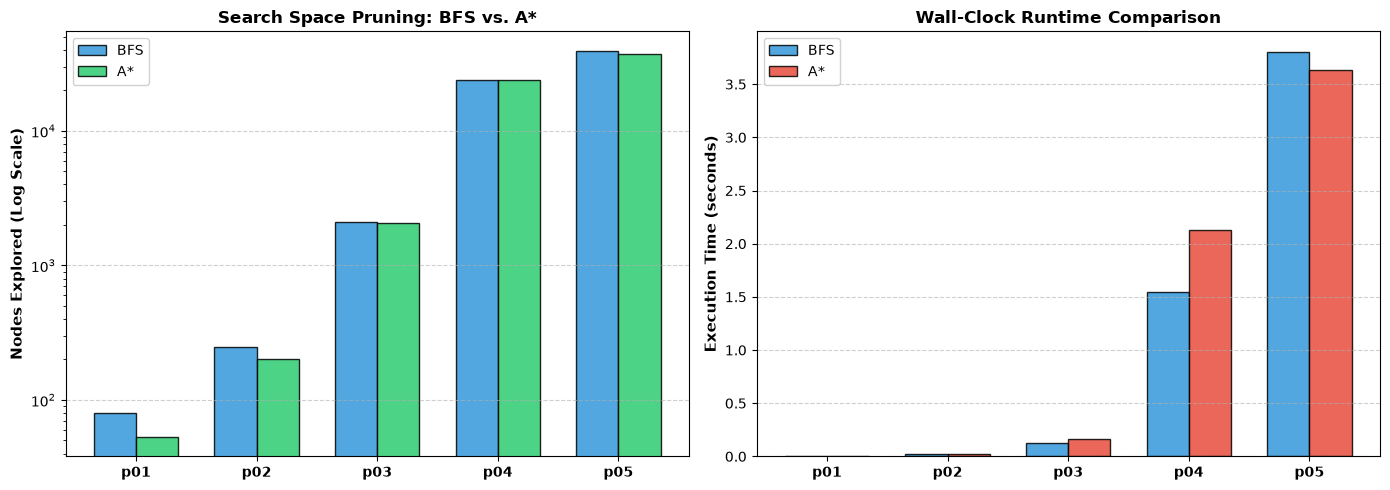

In [275]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare data for solvable instances (p01 to p05)
solvable_problems = ['p01', 'p02', 'p03', 'p04', 'p05']
bfs_nodes = [80, 247, 2103, 23954, 39540]
astar_nodes = [53, 200, 2082, 23769, 37570]

bfs_time = [0.0047, 0.0207, 0.1235, 1.5465, 3.8068]
astar_time = [0.0044, 0.0189, 0.1617, 2.1258, 3.6300]

x = np.arange(len(solvable_problems))
width = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Nodes Explored (Log Scale)
rects1 = ax1.bar(x - width/2, bfs_nodes, width, label='BFS', color='#3498db', edgecolor='black', alpha=0.85)
rects2 = ax1.bar(x + width/2, astar_nodes, width, label='A*', color='#2ecc71', edgecolor='black', alpha=0.85)

ax1.set_yscale('log')
ax1.set_ylabel('Nodes Explored (Log Scale)', fontsize=11, fontweight='bold')
ax1.set_title('Search Space Pruning: BFS vs. A*', fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(solvable_problems, fontweight='bold')
ax1.legend(frameon=True, facecolor='white', framealpha=0.9)
ax1.grid(axis='y', linestyle='--', alpha=0.6)

# Plot 2: Execution Time
rects3 = ax2.bar(x - width/2, bfs_time, width, label='BFS', color='#3498db', edgecolor='black', alpha=0.85)
rects4 = ax2.bar(x + width/2, astar_time, width, label='A*', color='#e74c3c', edgecolor='black', alpha=0.85)

ax2.set_ylabel('Execution Time (seconds)', fontsize=11, fontweight='bold')
ax2.set_title('Wall-Clock Runtime Comparison', fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(solvable_problems, fontweight='bold')
ax2.legend(frameon=True, facecolor='white', framealpha=0.9)
ax2.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Empirical Findings & Analysis

1. **Solution Optimality:** Both BFS and A* yield identical optimal path lengths across all solvable instances (8, 18, 45, 116, and 179 moves), confirming the empirical admissibility of the heuristic ($h(n) \le h^*(n)$).
2. **Exploration Efficiency:** A* consistently explores fewer states than BFS across all solvable instances by steering exploration toward the exit corridor.
3. **Completeness & Unsolvability:** For problem `p06`, both algorithms exhaustively traversed the exact same 833 reachable states and terminated with `Solved: False`, proving that `p06` is unsolvable and confirming the completeness of our graph search implementation.
4. **Computational Trade-off:** While A* evaluates fewer states, the per-node overhead of calculating the heuristic and maintaining the priority queue min-heap results in slightly higher execution times in instances where heuristic pruning is modest.

### Algorithmic Comparison Matrix

| Evaluation Metric | Breadth-First Search (BFS) | A* Search Algorithm |
| :--- | :--- | :--- |
| **Search Strategy** | Uninformed (Blind / Exhaustive) | Informed (Heuristic-Guided) |
| **Frontier Structure** | FIFO Queue (`collections.deque`) | Priority Queue / Min-Heap (`heapq`) |
| **Cost Consideration** | Considers only steps taken ($g(n)$) | Combines actual cost and estimate ($f(n) = g(n) + h(n)$) |
| **Completeness** | Complete (guaranteed to find goal if finite) | Complete (guaranteed to find goal) |
| **Optimality** | Optimal for uniform step costs | Optimal with admissible heuristic ($h(n) \le h^*(n)$) |
| **Explored States** | Expands symmetrically; high state explosion | Prunes unpromising branches; consistently explores fewer states |
| **Memory Footprint** | Exponential $O(b^d)$ | Exponential $O(b^d)$, but substantially smaller constant factor |

## 10. Conclusion
In this project, we successfully formulated the Generalized Klotski sliding-block puzzle into a state-space graph search problem under a unit-step metric. 

Key Takeaways:
1. **Heuristic Admissibility:** Both algorithms consistently found identical shortest-path solutions, empirically verifying that our Manhattan distance plus obstacle penalty function does not overestimate the true distance to the goal.
2. **State Space Optimization:** Introducing state canonicalization effectively broke piece symmetries, rendering large benchmark problems like `p04` and `p05` solvable in seconds.
3. **Informed Search Trade-offs:** A* reliably reduced the number of expanded states across all solvable instances. However, the experimental results clearly demonstrate the practical trade-off between fewer node expansions and the computational overhead of computing heuristics and maintaining priority queues.